In [1]:
import copy
import random
from collections import deque
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm

In [2]:
class QNetwork(nn.Module):
    def __init__(self, state_size=30, action_size=150, hidden_size=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(state_size, hidden_size), nn.ReLU(), nn.Linear(hidden_size, hidden_size), nn.ReLU(), nn.Linear(hidden_size, action_size))

    def forward(self, x):
        return self.net(x)

In [3]:
def estado_para_tensor(state, device):
    vetor = [-1.0 if state[p][a] is None else float(state[p][a]) / 4.0 for p in range(5) for a in range(6)]
    return torch.tensor(vetor, dtype=torch.float32, device=device)

In [4]:
def acao_para_idx(pos, atr, val):
    return pos * 30 + atr * 5 + val

def idx_para_acao(idx):
    pos, resto = divmod(idx, 30)
    atr, val = divmod(resto, 5)
    return pos, atr, val

In [5]:
regras = {
    (None, 1, 2): [lambda p, a, v: (None, 5, 0)],
    (None, 5, 0): [lambda p, a, v: (None, 1, 2), lambda p, a, v: ((p + 1, 4, 0), (p - 1, 4, 0))],
    (None, 3, 3): [lambda p, a, v: (None, 2, 0),lambda p, a, v: ((p + 1, 2, 1), (p - 1, 2, 1))],
    (None, 2, 0): [lambda p, a, v: (None, 3, 3)],
    (None, 1, 0): [lambda p, a, v: (None, 5, 2)],
    (None, 5, 2): [lambda p, a, v: (None, 1, 0)],
    (None, 1, 1): [lambda p, a, v: (p + 1, 1, 4), lambda p, a, v: (None, 0, 3), lambda p, a, v: (None, 4, 4)],
    (None, 1, 4): [lambda p, a, v: (p - 1, 1, 1)],
    (0, 1, 3): [lambda p, a, v: (0, 1, 3)],
    (4, 2, 0): [lambda p, a, v: (4, 2, 0)],
    (None, 5, 1): [lambda p, a, v: (None, 3, 1), lambda p, a, v: ((p + 1, 5, 3), (p - 1, 5, 3))],
    (None, 3, 1): [lambda p, a, v: (None, 5, 1)],
    (2, 5, 2): [lambda p, a, v: (2, 5, 2)],
    (None, 0, 3): [lambda p, a, v: (None, 1, 1)],
    (1, 4, 1): [lambda p, a, v: (1, 4, 1)],
    (None, 4, 2): [lambda p, a, v: (None, 0, 0)],
    (None, 0, 0): [lambda p, a, v: (None, 4, 2)],
    (None, 4, 0): [lambda p, a, v: ((p + 1, 5, 0), (p - 1, 5, 0)), lambda p, a, v: (None, 0, 4)],
    (None, 0, 4): [lambda p, a, v: (None, 4, 0)],
    (0, 0, 0): [lambda p, a, v: (0, 0, 0)],
    (None, 0, 1): [lambda p, a, v: (None, 3, 0)],
    (None, 3, 0): [lambda p, a, v: (None, 0, 1)],
    (None, 2, 1): [lambda p, a, v: ((p + 1, 3, 3), (p - 1, 3, 3)), lambda p, a, v: ((p + 1, 2, 4), (p - 1, 2, 4))],
    (None, 2, 2): [lambda p, a, v: (p + 1, 2, 3)],
    (None, 2, 3): [lambda p, a, v: (p - 1, 2, 2)],
    (None, 5, 3): [lambda p, a, v: ((p + 1, 5, 1), (p - 1, 5, 1))],
    (None, 4, 3): [lambda p, a, v: (None, 0, 2)],
    (None, 0, 2): [lambda p, a, v: (None, 4, 3)],
    (None, 5, 4): [lambda p, a, v: (None, 3, 4)],
    (None, 3, 4): [lambda p, a, v: (None, 5, 4)],
    (None, 2, 4): [lambda p, a, v: ((p + 1, 2, 1), (p - 1, 2, 1))],
    (None, 4, 4): [lambda p, a, v: (None, 1, 1)]
}

In [6]:
VAZIO = None

def recompensas(state, pos, atr, val):
    for p in range(5):
        if p != pos and state[p][atr] == val:
            return -10.0

    for (p_regra, a_regra, v_regra) in regras:
        if p_regra is not None and a_regra == atr:
            if v_regra == val and p_regra != pos:
                return -10.0
            if p_regra == pos and v_regra != val:
                return -10.0

    regras_abs = regras.get((pos, atr, val), [])
    regras_rel = regras.get((None, atr, val), [])

    if not regras_abs and not regras_rel:
        return 0.0

    recompensa_max = 0.0

    if regras_abs:
        recompensa_max = max(recompensa_max, 5.0)

    for func in regras_rel:
        resultado = func(pos, atr, val)

        if isinstance(resultado[0], tuple):
            pos_1, atr_alvo, valor_esperado = resultado[0]
            pos_2, _, _ = resultado[1]
            vizinhos = [p for p in (pos_1, pos_2) if 0 <= p < 5]

            valores_vizinhos = [state[p][atr_alvo] for p in vizinhos]
            if valor_esperado in valores_vizinhos:
                recompensa_max = max(recompensa_max, 2.0)
            elif VAZIO not in valores_vizinhos:
                return -10.0
        else:
            pos_alvo, atr_alvo, valor_esperado = resultado

            if pos_alvo is None:
                atual = state[pos][atr_alvo]
                if atual == valor_esperado:
                    recompensa_max = max(recompensa_max, 3.0)
                elif atual != VAZIO:
                    return -10.0
            else:
                if not (0 <= pos_alvo < 5):
                    return -10.0
                atual = state[pos_alvo][atr_alvo]
                if atual == valor_esperado:
                    recompensa_max = max(recompensa_max, 2.0)
                elif atual != VAZIO:
                    return -10.0

    return float(recompensa_max)

In [7]:
def buscar_acao(state):
    acoes_possiveis = []

    for atr in range(6):
        valores_usados = {state[p][atr] for p in range(5) if state[p][atr] != VAZIO}
        for pos in range(5):
            if state[pos][atr] == VAZIO:
                for val in range(5):
                    if val not in valores_usados:
                        r = recompensas(state, pos, atr, val)
                        acoes_possiveis.append((r, (pos, atr, val)))

    if not acoes_possiveis:
        return None, 0.0

    maior_recompensa = max(r for r, _ in acoes_possiveis)
    melhores_acoes = [acao for r, acao in acoes_possiveis if r == maior_recompensa]
    acao_escolhida = random.choice(melhores_acoes)

    return acao_escolhida, maior_recompensa

In [8]:
def epsilon_greedy_policy(q_network, state, epsilon, pos_preenc, atr_preenc, device="cpu"):
    acoes_validas = [(i, j, k) for i in range(5) for j in range(6) for k in range(5) if not pos_preenc[i][j] and not atr_preenc[j][k]]

    if not acoes_validas:
        return None

    if random.uniform(0, 1) < epsilon:
        return random.choice(acoes_validas)

    state_vec = torch.tensor([-1.0 if state[p][a] is None else float(state[p][a]) / 4.0 for p in range(5) for a in range(6)],dtype=torch.float32, device=device).unsqueeze(0)

    with torch.no_grad():
        q_values = q_network(state_vec).squeeze(0)

    melhor_acao = None
    maior_q_value = float("-inf")

    for pos, atr, val in acoes_validas:
        idx = pos * 30 + atr * 5 + val
        q_val = q_values[idx].item()
        if q_val > maior_q_value:
            maior_q_value = q_val
            melhor_acao = (pos, atr, val)

    return melhor_acao

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
state_size = 30
action_size = 150

q_network = QNetwork(state_size, action_size).to(device)

target_network = QNetwork(state_size, action_size).to(device)
target_network.load_state_dict(q_network.state_dict())
target_network.eval()

In [10]:
def gerar_mascara_validas(pos_preenc, atr_preenc):
    return torch.tensor([not pos_preenc[p][a] and not atr_preenc[a][v] for p in range(5) for a in range(6) for v in range(5)],dtype=torch.bool)

def train_dqn_einstein(n_training_episodes, max_epsilon, min_epsilon, decay_rate, C, gamma, learning_rate, batch_size, buffer_capacity):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    q_network = QNetwork(30, 150).to(device)
    target_network = QNetwork(30, 150).to(device)
    target_network.load_state_dict(q_network.state_dict())
    target_network.eval()

    optimizer = optim.Adam(q_network.parameters(), lr=learning_rate)
    criterion = nn.SmoothL1Loss()
    D = deque(maxlen=buffer_capacity)

    total_steps = 0
    historico_recompensas = []
    historico_passos = []

    for episode in tqdm(range(n_training_episodes)):
        state = [[VAZIO for _ in range(6)] for _ in range(5)]
        pos_preenc = np.zeros((5, 6), dtype=bool)
        atr_preenc = np.zeros((6, 5), dtype=bool)

        epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * episode)
        done = False
        passos_episodio = 0
        recompensa_episodio = 0.0

        while not done and passos_episodio < 30:
            action = epsilon_greedy_policy(
                q_network, state, epsilon, pos_preenc, atr_preenc, device
            )
            if action is None:
                break

            pos, atr, val = action
            reward = recompensas(state, pos, atr, val)

            # Aplica a ação em uma cópia independente do estado
            next_state = copy.deepcopy(state)
            next_state[pos][atr] = val
            pos_preenc[pos][atr] = True
            atr_preenc[atr][val] = True
            passos_episodio += 1

            # Verifica condições de término do episódio
            if reward == -10.0:
                done = True
            elif passos_episodio == 30:
                reward += 50.0
                done = True

            recompensa_episodio += reward

            # Prepara vetores e a máscara booleana de ações válidas do próximo estado
            state_vec = estado_para_tensor(state, "cpu")
            next_state_vec = estado_para_tensor(next_state, "cpu")
            action_idx = acao_para_idx(pos, atr, val)
            mascara_next = gerar_mascara_validas(pos_preenc, atr_preenc)

            D.append((
                state_vec,
                action_idx,
                float(reward),
                next_state_vec,
                float(done),
                mascara_next,
            ))

            state = next_state
            total_steps += 1

            # Treinamento com minibatch
            if len(D) >= batch_size:
                minibatch = random.sample(D, batch_size)
                (
                    states_b,
                    actions_b,
                    rewards_b,
                    next_states_b,
                    dones_b,
                    masks_next_b,
                ) = zip(*minibatch)

                states_t = torch.stack(states_b).to(device)
                actions_t = torch.tensor(actions_b, dtype=torch.int64, device=device).unsqueeze(1)
                rewards_t = torch.tensor(rewards_b, dtype=torch.float32, device=device)
                next_states_t = torch.stack(next_states_b).to(device)
                dones_t = torch.tensor(dones_b, dtype=torch.float32, device=device)
                masks_next_t = torch.stack(masks_next_b).to(device)

                # Cálculo do alvo y_i com máscara nas ações inválidas
                with torch.no_grad():
                    next_q_all = target_network(next_states_t)
                    next_q_all[~masks_next_t] = -1e9  # Bloqueia ações já ocupadas/inválidas
                    max_next_q = next_q_all.max(dim=1)[0]
                    # Zera o valor futuro caso não restem ações válidas no próximo estado
                    max_next_q = torch.where(
                        masks_next_t.any(dim=1),
                        max_next_q,
                        torch.zeros_like(max_next_q),
                    )
                    y = rewards_t + gamma * max_next_q * (1.0 - dones_t)

                # Passo de descida do gradiente com Huber Loss e Gradient Clipping
                q_sa = q_network(states_t).gather(1, actions_t).squeeze(1)
                loss = criterion(q_sa, y)

                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(q_network.parameters(), max_norm=1.0)
                optimizer.step()

            # Sincroniza pesos w^- <- w a cada C passos
            if total_steps % C == 0:
                target_network.load_state_dict(q_network.state_dict())

        historico_recompensas.append(recompensa_episodio)
        historico_passos.append(passos_episodio)

    return q_network, historico_recompensas, historico_passos

In [11]:
def avaliar_modelo(q_network, device="cpu"):
    q_network.eval()
    state = [[VAZIO for _ in range(6)] for _ in range(5)]
    pos_preenc = np.zeros((5, 6), dtype=bool)
    atr_preenc = np.zeros((6, 5), dtype=bool)

    recompensa_total = 0.0
    historico_jogadas = []

    for passo in range(30):
        action = epsilon_greedy_policy(q_network, state, epsilon=0.0, pos_preenc=pos_preenc, atr_preenc=atr_preenc, device=device)
        if action is None:
            break

        pos, atr, val = action
        reward = recompensas(state, pos, atr, val)
        recompensa_total += reward
        historico_jogadas.append((passo + 1, pos, atr, val, reward))

        state[pos][atr] = val
        pos_preenc[pos][atr] = True
        atr_preenc[atr][val] = True

        if reward == -10.0:
            print(f"❌ Erro fatal no passo {passo + 1}: Casa {pos}, Atributo {atr}, Valor {val} violou regra.")
            break


    nomes_atributos = ["Atributo 0", "Atributo 1", "Atributo 2", "Atributo 3", "Atributo 4", "Atributo 5"]
    print("\n=== TABULEIRO FINAL (TESTE DE EINSTEIN) ===")
    header = f"{'Atributo':<12} | " + " | ".join([f"Casa {p}" for p in range(5)])
    print(header)
    print("-" * len(header))

    for atr in range(6):
        linha = f"{nomes_atributos[atr]:<12} | " + " | ".join(
            [f"{str(state[p][atr]):^6}" for p in range(5)]
        )
        print(linha)

    print(f"\nRecompensa Total: {recompensa_total:.1f} | Células preenchidas: {len(historico_jogadas)}/30")
    return state, historico_jogadas

In [12]:
import matplotlib.pyplot as plt
import numpy as np

def plotar_resultados(recompensas_ep, passos_ep, janela=100):
    # Calcula a média móvel para suavizar o ruído da exploração epsilon-greedy
    media_rec = np.convolve(recompensas_ep, np.ones(janela)/janela, mode='valid')
    media_passos = np.convolve(passos_ep, np.ones(janela)/janela, mode='valid')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfico 1: Recompensa acumulada
    ax1.plot(recompensas_ep, alpha=0.2, color='blue', label='Por episódio')
    ax1.plot(range(janela - 1, len(recompensas_ep)), media_rec, color='blue', linewidth=2, label=f'Média móvel ({janela})')
    ax1.set_title("Evolução da Recompensa")
    ax1.set_xlabel("Episódio")
    ax1.set_ylabel("Recompensa Total")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Gráfico 2: Passos sobrevividos (máximo = 30)
    ax2.plot(passos_ep, alpha=0.2, color='green', label='Por episódio')
    ax2.plot(range(janela - 1, len(passos_ep)), media_passos, color='green', linewidth=2, label=f'Média móvel ({janela})')
    ax2.axhline(30, color='red', linestyle='--', label='Tabuleiro Completo (30)')
    ax2.set_title("Células Preenchidas Antes de Errar")
    ax2.set_xlabel("Episódio")
    ax2.set_ylabel("Passos")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [13]:
def inspecionar_top_acoes(q_network, state, device="cpu", top_k=5):
    q_network.eval()
    state_t = estado_para_tensor(state, device).unsqueeze(0)
    with torch.no_grad():
        q_vals = q_network(state_t).squeeze(0)

    top_valores, top_indices = torch.topk(q_vals, top_k)
    print(f"Top {top_k} ações mais valorizadas pela rede no estado atual:")
    for val_q, idx in zip(top_valores, top_indices):
        pos, atr, val = idx_para_acao(int(idx.item()))
        print(f"  -> Casa {pos}, Atributo {atr}, Valor {val} | Q-Value previsto: {val_q.item():.3f}")

In [14]:
n_training_episodes=20000
max_epsilon=1.0
min_epsilon=0.05
decay_rate=0.0005
C=500
gamma=0.95
learning_rate=1e-4
batch_size=64
buffer_capacity=50000

In [ ]:
q_network, rec_ep, passos_ep = train_dqn_einstein(n_training_episodes,max_epsilon,min_epsilon,decay_rate,C,gamma,learning_rate,batch_size,buffer_capacity)

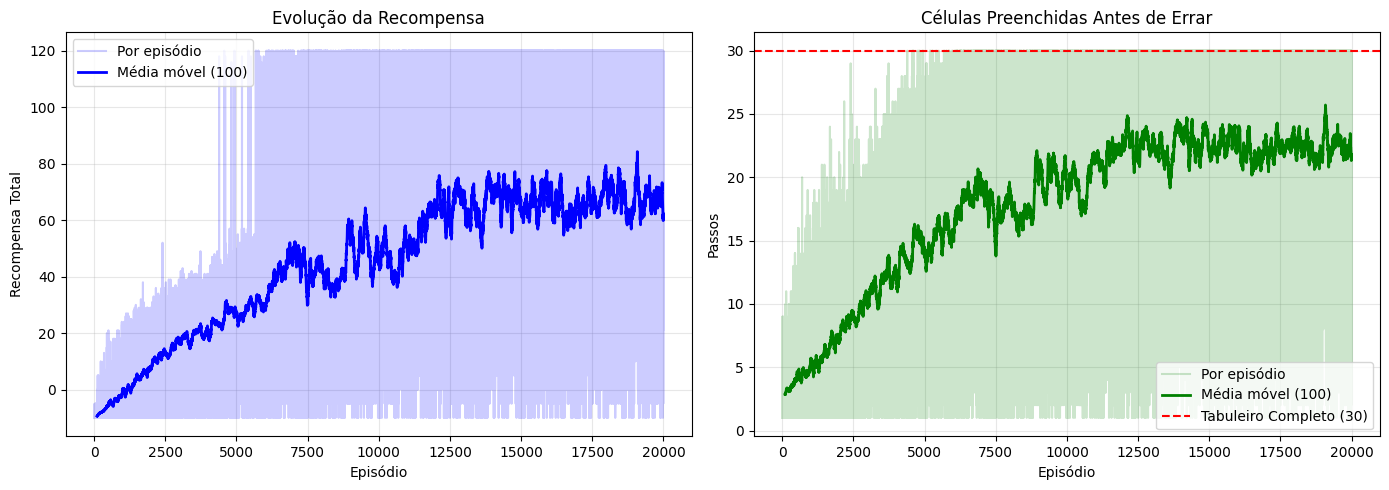


=== TABULEIRO FINAL (TESTE DE EINSTEIN) ===
Atributo     | Casa 0 | Casa 1 | Casa 2 | Casa 3 | Casa 4
---------------------------------------------------------
Atributo 0   |   0    |   1    |   4    |   3    |   2   
Atributo 1   |   3    |   2    |   0    |   1    |   4   
Atributo 2   |   2    |   3    |   4    |   1    |   0   
Atributo 3   |   4    |   0    |   2    |   1    |   3   
Atributo 4   |   2    |   1    |   0    |   4    |   3   
Atributo 5   |   4    |   0    |   2    |   1    |   3   

Recompensa Total: 70.0 | Células preenchidas: 30/30


([[0, 3, 2, 4, 2, 4],
  [1, 2, 3, 0, 1, 0],
  [4, 0, 4, 2, 0, 2],
  [3, 1, 1, 1, 4, 1],
  [2, 4, 0, 3, 3, 3]],
 [(1, 0, 0, 0, 5.0),
  (2, 4, 2, 0, 5.0),
  (3, 0, 1, 3, 5.0),
  (4, 2, 0, 4, 0.0),
  (5, 2, 4, 0, 3.0),
  (6, 4, 3, 3, 3.0),
  (7, 1, 5, 0, 2.0),
  (8, 3, 2, 1, 2.0),
  (9, 1, 1, 2, 3.0),
  (10, 2, 3, 2, 0.0),
  (11, 2, 2, 4, 2.0),
  (12, 0, 4, 2, 3.0),
  (13, 4, 5, 3, 0.0),
  (14, 1, 0, 1, 0.0),
  (15, 4, 0, 2, 0.0),
  (16, 1, 2, 3, 0.0),
  (17, 4, 1, 4, 0.0),
  (18, 0, 3, 4, 0.0),
  (19, 4, 4, 3, 3.0),
  (20, 3, 1, 1, 2.0),
  (21, 0, 5, 4, 3.0),
  (22, 3, 0, 3, 3.0),
  (23, 1, 3, 0, 3.0),
  (24, 0, 2, 2, 2.0),
  (25, 2, 5, 2, 5.0),
  (26, 1, 4, 1, 5.0),
  (27, 3, 5, 1, 2.0),
  (28, 3, 4, 4, 3.0),
  (29, 2, 1, 0, 3.0),
  (30, 3, 3, 1, 3.0)])

In [17]:
plotar_resultados(rec_ep, passos_ep)
avaliar_modelo(q_network, device=next(q_network.parameters()).device)